# House Prices: Exploratory Data Analysis
### What makes a house more expensive?

In this notebook I explore the House Prices dataset. I look at how sale prices are distributed and which features of a house are related to its price.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
sns.set_theme(style="white")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = "../DATA/train.csv"
RESULTS = "../RESULTS/"
os.makedirs(RESULTS, exist_ok=True)

def save(name):
    plt.savefig(RESULTS + name, dpi=150, bbox_inches="tight")

## The Dataset

In [2]:
houses = pd.read_csv(DATA_PATH)
print(f"{houses.shape[0]} houses and {houses.shape[1]} columns")
houses.head()

1460 houses and 81 columns


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Missing Values

In [3]:
missing = pd.DataFrame({
    "Missing values": houses.isna().sum(),
    "Missing (%)": (houses.isna().mean() * 100).round(1)
})
missing = missing[missing["Missing values"] > 0].sort_values("Missing (%)", ascending=False)

missing.head(10)

,Missing values,Missing (%)
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


Most missing values simply mean that **the house does not have that feature**. For example, almost no house has a
pool (`PoolQC`), most have no alley access (`Alley`) or fence (`Fence`), and about half have no fireplace
(`FireplaceQu`).

## Sale Prices

In [4]:
houses["SalePrice"].describe().round(0)

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

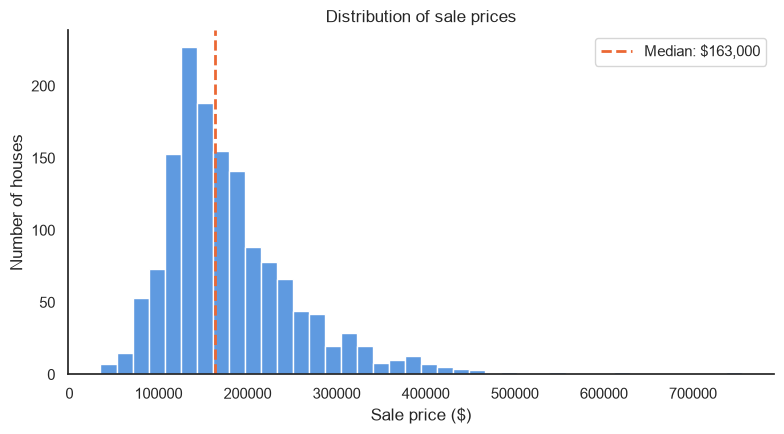

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(houses["SalePrice"], bins=40, color=BLUE, ax=ax)
ax.axvline(houses["SalePrice"].median(), color=ORANGE, lw=2, ls="--",
           label=f"Median: ${houses['SalePrice'].median():,.0f}")
ax.set_xlabel("Sale price ($)")
ax.set_ylabel("Number of houses")
ax.set_title("Distribution of sale prices")
ax.legend()
plt.tight_layout()
save("Saleprice_distribution.png")
plt.show()

A typical house sold for about 163,000, most houses sold between 130,000 and 214,000. A few very expensive houses (up to 755,000) create a long tail to the right, which is why the average price (180,921) is higher than the median.

## Correlation with Sales Price

In [6]:
numeric = houses.select_dtypes(include="number").drop(columns="Id")
corr_price = numeric.corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
corr_price.head(10).round(2)

OverallQual     0.79
GrLivArea       0.71
GarageCars      0.64
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
FullBath        0.56
TotRmsAbvGrd    0.53
YearBuilt       0.52
YearRemodAdd    0.51
Name: SalePrice, dtype: float64

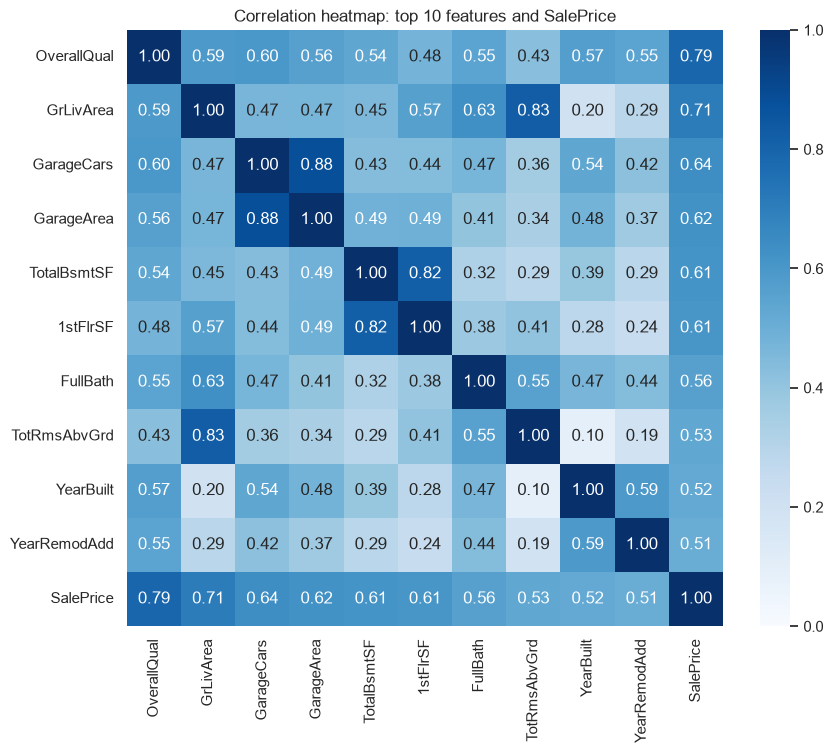

In [7]:
top = corr_price.head(10).index.tolist() + ["SalePrice"]
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(houses[top].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax)
ax.set_title("Correlation heatmap: top 10 features and SalePrice")
plt.tight_layout()
save("Correlation_heatmap.png")
plt.show()

The features most related to price are "overall quality" (0.79) and "living area" (0.71). Garage size, basement
size, number of bathrooms and the year the house was built also have a positive relationship with price. Some
features are closely related to each other too, for example garage size and garage area, because they measure almost
the same thing.

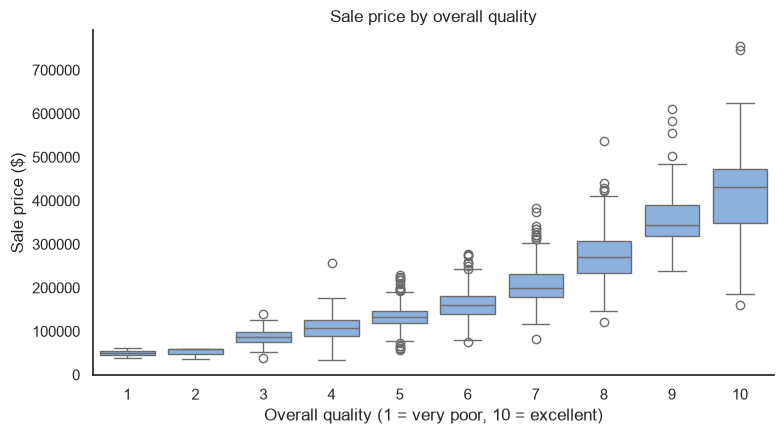

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=houses, x="OverallQual", y="SalePrice", color="#7fb0ea", ax=ax)
ax.set_xlabel("Overall quality (1 = very poor, 10 = excellent)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Sale price by overall quality")
plt.tight_layout()
save("Price_by_quality.png")
plt.show()

Higher quality houses clearly sell for more: prices go up with every quality level

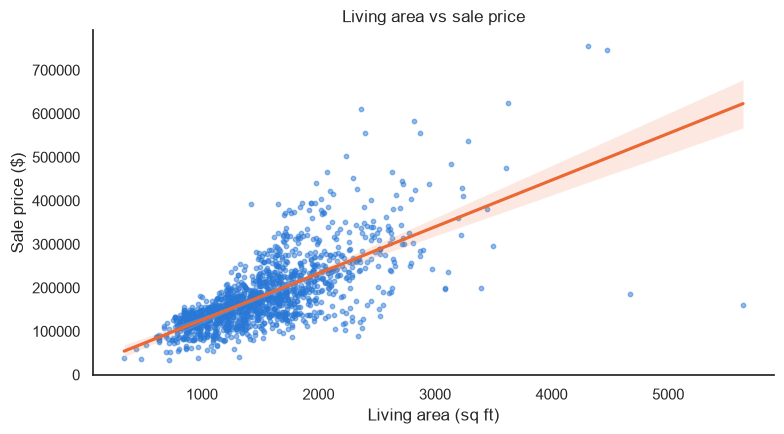

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=houses, x="GrLivArea", y="SalePrice", color=BLUE,
            scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": ORANGE}, ax=ax)
ax.set_xlabel("Living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Living area vs sale price")
plt.tight_layout()
save("Living_area_vs_price.png")
plt.show()

Bigger houses tend to sell for more. A couple of very large houses sold for unusually low prices

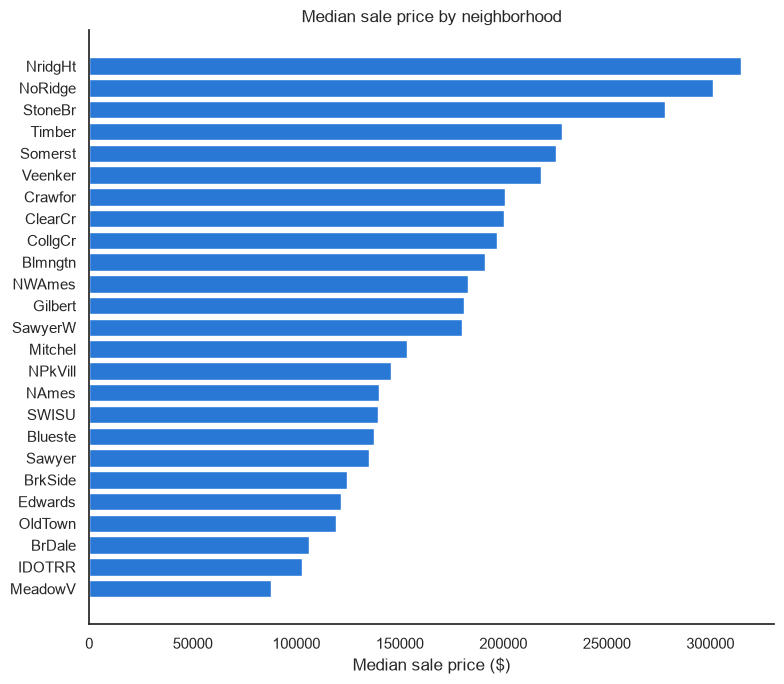

In [10]:
neighborhoods = houses.groupby("Neighborhood")["SalePrice"].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(neighborhoods.index, neighborhoods.values, color=BLUE)
ax.set_xlabel("Median sale price ($)")
ax.set_title("Median sale price by neighborhood")
plt.tight_layout()
save("Price_by_neighborhood.png")
plt.show()

Location matters: houses in the most expensive neighborhoods cost more than three times as much as in the cheapest ones

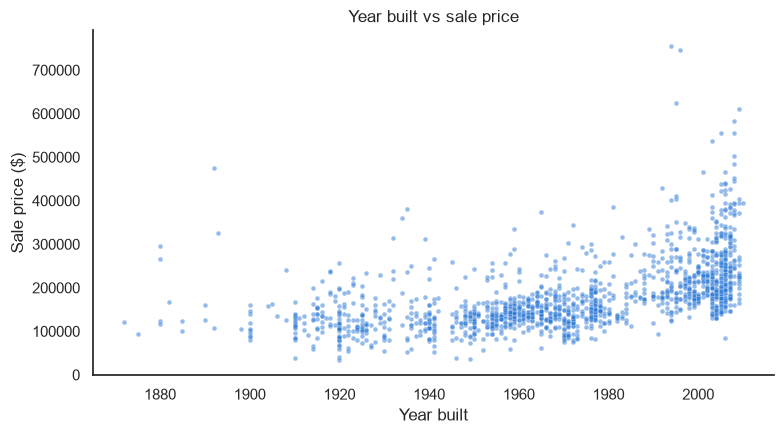

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=houses, x="YearBuilt", y="SalePrice", color=BLUE, s=12, alpha=0.5, ax=ax)
ax.set_xlabel("Year built")
ax.set_ylabel("Sale price ($)")
ax.set_title("Year built vs sale price")
plt.tight_layout()
save("Year_built_vs_price.png")
plt.show()

Newer houses usually sell for more than older ones

In [12]:
# Key numbers used in the one-page summary
median = houses.groupby("OverallQual")["SalePrice"].median()
print(f"Quality 5 (average):   ${median[5]:,.0f}   |   Quality 10 (excellent): ${median[10]:,.0f}")
print(f"Most expensive neighborhood:  {neighborhoods.index[-1]} ${neighborhoods.iloc[-1]:,.0f}")
print(f"Cheapest neighborhood:        {neighborhoods.index[0]} ${neighborhoods.iloc[0]:,.0f}")
built = pd.cut(houses["YearBuilt"], [1870, 1950, 1980, 2000, 2010],
               labels=["Before 1950", "1951-1980", "1981-2000", "2001-2010"])
houses.groupby(built, observed=True)["SalePrice"].median().rename("Median price by year built")

Quality 5 (average):   $133,000   |   Quality 10 (excellent): $432,390
Most expensive neighborhood:  NridgHt $315,000
Cheapest neighborhood:        MeadowV $88,000


YearBuilt
Before 1950    122250.0
1951-1980      143000.0
1981-2000      197200.0
2001-2010      224700.0
Name: Median price by year built, dtype: float64

## Conclusion

* A typical house sold for about $163,000, with a few expensive houses pulling the average up.
* The houses that sell for more are usually higher quality, larger, newer and in better neighborhoods.
  Overall quality and living area are the features most related to price.
* Many missing values just mean the house does not have that feature (for example, no pool or no fence).
* Correlation shows relationships, not causes: for example, high-quality houses also tend to be bigger and newer.